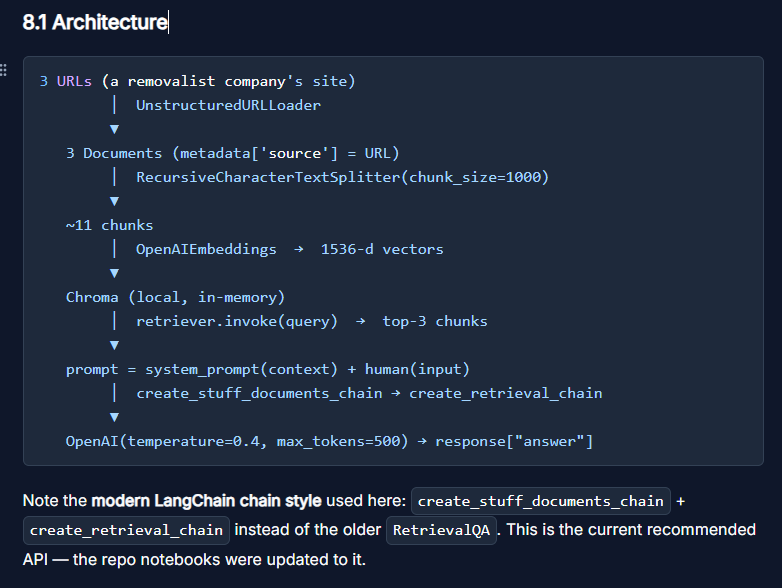

In [48]:
!pip install -q langchain langchain-classic langchain-community langchain-groq \
    langchain-chroma langchain-huggingface langchain-text-splitters \
    sentence-transformers unstructured

In [49]:
import os
from google.colab import userdata

os.environ["GROQ_API_KEY"] = userdata.get("GROQ_API_KEY")

In [50]:
# load the website
from langchain_community.document_loaders import UnstructuredURLLoader

urls = [
    'https://www.victoriaonmove.com.au/local-removalists.html',
    'https://victoriaonmove.com.au/index.html',
    'https://victoriaonmove.com.au/contact.html',
]

loader = UnstructuredURLLoader(urls=urls)
data = loader.load()

print(len(data))                 # 3 -> one Document per URL
print(data[0].metadata)          # {'source': '<url>'}
print(data[0].page_content[:300])

3
{'source': 'https://www.victoriaonmove.com.au/local-removalists.html'}
Local Removalists Melbourne

Top-notch local moving services tailored to your needs — from studio apartments to large family homes.

What We Do

Comprehensive Local Moving Services

We offer a full range of local moving services for Melbourne residents and businesses. Our experienced team handles ev


In [51]:
#split into chunks
from langchain_text_splitters import RecursiveCharacterTextSplitter

text_splitter = RecursiveCharacterTextSplitter(chunk_size=1000)
docs = text_splitter.split_documents(data)

print("Total chunks:", len(docs))     # roughly 11
print(docs[0].page_content)

Total chunks: 16
Local Removalists Melbourne

Top-notch local moving services tailored to your needs — from studio apartments to large family homes.

What We Do

Comprehensive Local Moving Services

We offer a full range of local moving services for Melbourne residents and businesses. Our experienced team handles every move with care and professionalism.

Apartment Moving

Efficient and careful relocation services tailored for apartments of all sizes. We navigate lifts, stairs, and narrow corridors with ease.

Villa Moving

Comprehensive moving solutions for large residences and villas. We handle your valuable possessions with the utmost care and attention.

Household Moving

Full-service moving options for households of every size, including packing, loading, transportation, and unpacking at your new home.

Office Moving

Specialised expertise in office relocations. We minimise downtime and ensure your business is up and running as quickly as possible.

Furniture Moving


In [52]:
#Embeddings+Vector store
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_chroma import Chroma

embeddings = HuggingFaceEmbeddings(model_name="sentence-transformers/all-MiniLM-L6-v2")

vectorstore = Chroma.from_documents(documents=docs, embedding=embeddings)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

In [53]:
#Retriever
retriever = vectorstore.as_retriever(search_type="similarity", search_kwargs={"k": 3})

retrieved_docs = retriever.invoke("What kind of services they provide?")
print(len(retrieved_docs))            # 3

for i, d in enumerate(retrieved_docs):
    print(f"--- chunk {i} | {d.metadata['source']}")
    print(d.page_content[:300])

3
--- chunk 0 | https://victoriaonmove.com.au/index.html
Unlike some other moving companies, we value the trust our customers place in us. Our customer reviews on Google are genuine, and we never manipulate them. Every 5-star review is earned through hard work and exceptional service.

Fully Insured

Transit and public liability insurance on every move. Y
--- chunk 1 | https://victoriaonmove.com.au/index.html
Unlike some other moving companies, we value the trust our customers place in us. Our customer reviews on Google are genuine, and we never manipulate them. Every 5-star review is earned through hard work and exceptional service.

Fully Insured

Transit and public liability insurance on every move. Y
--- chunk 2 | https://victoriaonmove.com.au/index.html
Unlike some other moving companies, we value the trust our customers place in us. Our customer reviews on Google are genuine, and we never manipulate them. Every 5-star review is earned through hard work and exceptional service.

F

In [54]:
#The LLM
from langchain_groq import ChatGroq

llm = ChatGroq(
    model="openai/gpt-oss-20b",   # or "llama-3.1-8b-instant" (faster, smaller)
    temperature=0.4,
    max_tokens=500,
)

In [55]:
#The prompt
from langchain_core.prompts import ChatPromptTemplate

system_prompt = (
    "You are an assistant for question-answering tasks. "
    "Answer ONLY using the retrieved context below. "
    "Do not use any outside knowledge, even if you know the answer. "
    "If the answer is not in the context, reply exactly: "
    "\"I don't know based on the provided website.\" "
    "Use three sentences maximum.\n\n"
    "{context}"
)


prompt = ChatPromptTemplate.from_messages([
    ("system", system_prompt),
    ("human", "{input}"),
])
# Why: This is the “augmentation” step. Three parts do the work:

#“Use the retrieved context” grounds the answer in your documents.
#“If you don’t know, say so” stops the model from making things up.
#“Three sentences maximum” controls the length.

In [56]:
#Build the chain
try:
    from langchain.chains import create_retrieval_chain
    from langchain.chains.combine_documents import create_stuff_documents_chain
except ImportError:
    from langchain_classic.chains import create_retrieval_chain
    from langchain_classic.chains.combine_documents import create_stuff_documents_chain

question_answer_chain = create_stuff_documents_chain(llm, prompt)
rag_chain = create_retrieval_chain(retriever, question_answer_chain)

In [57]:
from groq import Groq
import os

client = Groq(api_key=os.environ["GROQ_API_KEY"])
for m in client.models.list().data:
    print(m.id)

canopylabs/orpheus-v1-english
meta-llama/llama-prompt-guard-2-22m
allam-2-7b
whisper-large-v3-turbo
openai/gpt-oss-20b
qwen/qwen3.8-27b
meta-llama/llama-prompt-guard-2-86m
openai/gpt-oss-safeguard-20b
openai/gpt-oss-120b
canopylabs/orpheus-arabic-saudi
whisper-large-v3


In [58]:
#ask the question
response = rag_chain.invoke({"input": "What kind of services they provide?"})
print(response["answer"])

They offer moving services, including interstate routes. All moves are fully insured with transit and public liability coverage from loading to delivery. Pricing is transparent, with hourly rates and no hidden fees.


In [59]:
#show which pages the answers came from
for d in response["context"]:
    print(d.metadata["source"])

https://victoriaonmove.com.au/index.html
https://victoriaonmove.com.au/index.html
https://victoriaonmove.com.au/index.html


In [60]:
#Test the “don’t know” clause
print(rag_chain.invoke({"input": "Who won the 2022 football world cup?"})["answer"])

I don't know based on the provided website.


In [61]:
#streamlit
%%writefile app.py
import os
import streamlit as st
from langchain_groq import ChatGroq
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_community.document_loaders import UnstructuredURLLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_chroma import Chroma
from langchain_core.prompts import ChatPromptTemplate
try:
    from langchain.chains import create_retrieval_chain
    from langchain.chains.combine_documents import create_stuff_documents_chain
except ImportError:
    from langchain_classic.chains import create_retrieval_chain
    from langchain_classic.chains.combine_documents import create_stuff_documents_chain

st.title("RAG App Demo")

urls = ['https://www.victoriaonmove.com.au/local-removalists.html',
        'https://victoriaonmove.com.au/index.html',
        'https://victoriaonmove.com.au/contact.html']

system_prompt = (
    "You are an assistant for question-answering tasks. "
    "Use the following pieces of retrieved context to answer "
    "the question. If you don't know the answer, say that you "
    "don't know. Use three sentences maximum and keep the "
    "answer concise.\n\n{context}"
)
prompt = ChatPromptTemplate.from_messages([("system", system_prompt), ("human", "{input}")])

@st.cache_resource
def build_chain():
    data = UnstructuredURLLoader(urls=urls).load()
    docs = RecursiveCharacterTextSplitter(chunk_size=1000).split_documents(data)
    emb = HuggingFaceEmbeddings(model_name="sentence-transformers/all-MiniLM-L6-v2")
    vs = Chroma.from_documents(documents=docs, embedding=emb)
    ret = vs.as_retriever(search_type="similarity", search_kwargs={"k": 6})
    llm = ChatGroq(model="llama-3.3-70b-versatile", temperature=0.4, max_tokens=500)
    qa = create_stuff_documents_chain(llm, prompt)
    return create_retrieval_chain(ret, qa)

rag_chain = build_chain()

query = st.chat_input("Ask me anything: ")
if query:
    response = rag_chain.invoke({"input": query})
    st.write(response["answer"])

Overwriting app.py


In [62]:
!pip install -q streamlit
!streamlit run app.py &>/content/logs.txt &
!npx localtunnel --port 8501

ERROR: Operation cancelled by user
⠙^C
